# AML 01 — Dataset preparation, EDA, preprocessing, and features

This notebook is the project source of truth for raw-data checks, the shared AML split, train-only RSSI scaling, and reusable feature construction. It reads only the repository's raw files and exports prepared train, internal-validation, and held-out-validation tables as plain CSV files under the existing `data/processed/` directory.

The supplied `validationData.csv` stays held out for final evaluation. Its EDA below is descriptive only. All learned scaling parameters are fitted on the grouped internal-training partition, then reused unchanged for internal validation and held-out validation.

**Project:** Project 9 — Indoor Location Prediction Using Wi-Fi Signals  
**Phase:** AML (Phase 1)  
**Pipeline:** Data Preparation and Feature Engineering

## Notebook navigation

- [1. Environment and configuration](#---)
- [2. Load files and validate the observed schema](#-------)
- [3. Data quality and verified Wi-Fi signal convention](#-----w---)
- [4. Exploratory data analysis](#---)
- [5. Shared AML development split](#----)
- [6. Train-only RSSI scaling and shared feature functions](#--------)
- [7. Prepare the three shared datasets](#-----)
- [8. Export plain CSV files, reload, and verify](#-------)
- [Conclusion](#)
- [Next Steps](#-)


## 1. Environment and configuration

Imports, reproducibility settings, and repository-relative paths are initialized in the code cells below. This notebook is designed to run independently from a fresh kernel.


**Cell purpose:** Imports the required packages and reports the active Python environment.


In [1]:
from pathlib import Path
import platform
import re
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit

print(f"Python: {platform.python_version()} ({sys.executable})")
print(f"NumPy: {np.__version__}; pandas: {pd.__version__}; scikit-learn: {__import__('sklearn').__version__}; matplotlib: {plt.matplotlib.__version__}")



Python: 3.14.2 (/Users/Krishiv/Desktop/Signal2Space/.venv/bin/python)
NumPy: 2.5.4; pandas: 3.0.6; scikit-learn: 1.9.1; matplotlib: 3.11.2


**Cell purpose:** Locates the repository and defines the canonical input and output directories.


In [2]:
def find_project_root(start=None):
    candidate = Path.cwd() if start is None else Path(start)
    for parent in (candidate, *candidate.parents):
        if (parent / "data/raw/trainingData.csv").is_file() and (parent / "Machine Learning Pipeline").is_dir():
            return parent
    raise FileNotFoundError("Could not locate repository root from the current working directory")

PROJECT_ROOT = find_project_root()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR = PROJECT_ROOT / "data" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_PATH = RAW_DIR / "trainingData.csv"
HELDOUT_PATH = RAW_DIR / "validationData.csv"
assert TRAIN_PATH.is_file() and HELDOUT_PATH.is_file()
assert PROCESSED_DIR.is_dir(), "Expected existing data/processed/ directory"
print("Repository root:", PROJECT_ROOT)
print("Repository-relative inputs:", TRAIN_PATH.relative_to(PROJECT_ROOT), HELDOUT_PATH.relative_to(PROJECT_ROOT))


Repository root: /Users/Krishiv/Desktop/Signal2Space
Repository-relative inputs: data/raw/trainingData.csv data/raw/validationData.csv


## 2. Load files and validate the observed schema

WAP predictors are discovered from column names matching `WAP` followed by digits and ordered by numeric suffix. Targets and metadata are selected only after checking that the required fields are present in the actual files. Dataset meanings beyond the available field names are not assumed.


**Cell purpose:** Loads the raw training and supplied held-out datasets.


In [3]:
train_raw = pd.read_csv(TRAIN_PATH)
heldout_raw = pd.read_csv(HELDOUT_PATH)
RAW_COLUMNS = train_raw.columns.tolist()
AP_COLUMNS = sorted([c for c in RAW_COLUMNS if re.fullmatch(r"WAP\d+", str(c))], key=lambda c: int(c[3:]))
TARGET_COLUMNS = ["BUILDINGID", "FLOOR", "LONGITUDE", "LATITUDE"]
METADATA_COLUMNS = ["SPACEID", "RELATIVEPOSITION", "USERID", "PHONEID", "TIMESTAMP"]



**Cell purpose:** Defines and applies schema checks, then assigns stable source row identifiers.


In [4]:
def validate_raw_schema(frame, expected_columns, name):
    if frame.columns.tolist() != expected_columns:
        raise ValueError(f"{name} has unexpected columns or column order")
    required = TARGET_COLUMNS + METADATA_COLUMNS
    missing_fields = [c for c in required if c not in frame.columns]
    if missing_fields:
        raise ValueError(f"{name} is missing required targets/metadata: {missing_fields}")
    blank_counts = frame.isna().sum()
    if blank_counts.any():
        raise ValueError(f"{name} has blank cells: {blank_counts[blank_counts > 0].to_dict()}")

validate_raw_schema(train_raw, RAW_COLUMNS, "trainingData.csv")
validate_raw_schema(heldout_raw, RAW_COLUMNS, "validationData.csv")
assert AP_COLUMNS and AP_COLUMNS == [f"WAP{i:03d}" for i in range(1, len(AP_COLUMNS) + 1)]
assert len(AP_COLUMNS) == 520, f"Observed WAP count differs from this dataset schema: {len(AP_COLUMNS)}"
train_raw = train_raw.copy()
heldout_raw = heldout_raw.copy()
train_raw.insert(0, "ROW_ID", np.arange(len(train_raw), dtype=np.int32))
heldout_raw.insert(0, "ROW_ID", np.arange(len(heldout_raw), dtype=np.int32))



**Cell purpose:** Summarizes observed columns, targets, metadata, types, and partition dimensions.


In [5]:
schema_summary = pd.DataFrame({
    "dtype": train_raw[RAW_COLUMNS].dtypes.astype(str),
    "training_non_null": train_raw[RAW_COLUMNS].notna().sum(),
    "heldout_non_null": heldout_raw[RAW_COLUMNS].notna().sum(),
})
print("trainingData.csv rows × raw columns:", train_raw.shape[0], len(RAW_COLUMNS))
print("validationData.csv rows × raw columns:", heldout_raw.shape[0], len(RAW_COLUMNS))
print("Verified WAP columns:", AP_COLUMNS[0], "through", AP_COLUMNS[-1], "(contiguous numeric suffixes)")
print("Target fields:", TARGET_COLUMNS, "| collection metadata:", METADATA_COLUMNS)
print("Raw dtype counts:", train_raw[RAW_COLUMNS].dtypes.astype(str).value_counts().to_dict())
print("Building labels:", sorted(train_raw.BUILDINGID.unique().tolist()), "| floor labels:", sorted(train_raw.FLOOR.unique().tolist()))
print("Target availability in held-out file:", {c: int(heldout_raw[c].notna().sum()) for c in TARGET_COLUMNS})
display(schema_summary.loc[TARGET_COLUMNS + METADATA_COLUMNS])


trainingData.csv rows × raw columns: 19937 529
validationData.csv rows × raw columns: 1111 529
Verified WAP columns: WAP001 through WAP520 (contiguous numeric suffixes)
Target fields: ['BUILDINGID', 'FLOOR', 'LONGITUDE', 'LATITUDE'] | collection metadata: ['SPACEID', 'RELATIVEPOSITION', 'USERID', 'PHONEID', 'TIMESTAMP']
Raw dtype counts: {'int64': 527, 'float64': 2}
Building labels: [0, 1, 2] | floor labels: [0, 1, 2, 3, 4]
Target availability in held-out file: {'BUILDINGID': 1111, 'FLOOR': 1111, 'LONGITUDE': 1111, 'LATITUDE': 1111}


,dtype,training_non_null,heldout_non_null
BUILDINGID,int64,19937,1111
FLOOR,int64,19937,1111
LONGITUDE,float64,19937,1111
LATITUDE,float64,19937,1111
SPACEID,int64,19937,1111
RELATIVEPOSITION,int64,19937,1111
USERID,int64,19937,1111
PHONEID,int64,19937,1111
TIMESTAMP,int64,19937,1111


## 3. Data quality and verified Wi-Fi signal convention

The UJIIndoorLoc signal encoding is verified from the supplied values. `100` is treated as absent because it is the dominant non-RSSI value; all other observed values are nonpositive in both files. Exact duplicates and all-missing Wi-Fi rows are counted and retained because no repository evidence justifies deleting them.


**Cell purpose:** Defines the missing-signal sentinel and builds observed-signal masks.


In [6]:
MISSING_SIGNAL = 100
train_signal_array = train_raw[AP_COLUMNS].to_numpy(dtype=np.int16, copy=True)
heldout_signal_array = heldout_raw[AP_COLUMNS].to_numpy(dtype=np.int16, copy=True)
train_seen_array = train_signal_array != MISSING_SIGNAL
heldout_seen_array = heldout_signal_array != MISSING_SIGNAL
assert train_seen_array.any() and (~train_seen_array).any()
assert np.all(train_signal_array[train_seen_array] <= 0), "Unexpected nonpositive RSSI convention in training data"
assert np.all(heldout_signal_array[heldout_seen_array] <= 0), "Unexpected signal value in held-out data"



**Cell purpose:** Measures missingness, duplicate rows, empty scans, and exact overlap across partitions.


In [7]:
train_duplicate_count = int(train_raw[RAW_COLUMNS].duplicated().sum())
heldout_duplicate_count = int(heldout_raw[RAW_COLUMNS].duplicated().sum())
train_blank_count = int(train_raw[RAW_COLUMNS].isna().sum().sum())
heldout_blank_count = int(heldout_raw[RAW_COLUMNS].isna().sum().sum())
train_zero_ap_rows = int((train_seen_array.sum(axis=1) == 0).sum())
heldout_zero_ap_rows = int((heldout_seen_array.sum(axis=1) == 0).sum())
train_observed_values = train_signal_array[train_seen_array]
heldout_observed_values = heldout_signal_array[heldout_seen_array]

# This hash comparison is descriptive partition checking only; no held-out values fit preprocessing.
train_hashes = pd.util.hash_pandas_object(train_raw[RAW_COLUMNS], index=False).to_numpy()
heldout_hashes = pd.util.hash_pandas_object(heldout_raw[RAW_COLUMNS], index=False).to_numpy()
exact_overlap_hashes = int(np.intersect1d(train_hashes, heldout_hashes).size)
quality_summary = pd.DataFrame([
    {"check": "exact duplicate raw rows", "training": train_duplicate_count, "heldout_descriptive": heldout_duplicate_count},
    {"check": "blank cells", "training": train_blank_count, "heldout_descriptive": heldout_blank_count},
    {"check": "rows with zero detected APs", "training": train_zero_ap_rows, "heldout_descriptive": heldout_zero_ap_rows},
    {"check": "missing WAP values encoded as 100", "training": int((~train_seen_array).sum()), "heldout_descriptive": int((~heldout_seen_array).sum())},
])
print("Observed signal min/max dBm (training):", int(train_observed_values.min()), int(train_observed_values.max()))
print("Observed signal min/max dBm (held-out, descriptive):", int(heldout_observed_values.min()), int(heldout_observed_values.max()))
print("Training missing-signal prevalence:", round(float((~train_seen_array).mean()), 6))
print("Held-out missing-signal prevalence (descriptive):", round(float((~heldout_seen_array).mean()), 6))
print("Exact raw-row hash overlap across supplied partitions:", exact_overlap_hashes)
print("Held-out placeholder metadata:", {c: heldout_raw[c].value_counts().to_dict() for c in ["SPACEID", "RELATIVEPOSITION", "USERID"]})
display(quality_summary)
assert exact_overlap_hashes == 0


Observed signal min/max dBm (training): -104 0
Observed signal min/max dBm (held-out, descriptive): -102 -34
Training missing-signal prevalence: 0.965395
Held-out missing-signal prevalence (descriptive): 0.968317
Exact raw-row hash overlap across supplied partitions: 0
Held-out placeholder metadata: {'SPACEID': {0: 1111}, 'RELATIVEPOSITION': {0: 1111}, 'USERID': {0: 1111}}


,check,training,heldout_descriptive
0,exact duplicate raw rows,637,0
1,blank cells,0,0
2,rows with zero detected APs,76,0
3,missing WAP values encoded as 100,10008477,559416


## 4. Exploratory data analysis

These plots describe the raw partitions. Training summaries and labels inform the data handoff; held-out validation points are shown only as descriptive comparisons. No held-out result is used to select features, choose a scaler, or tune preprocessing.


**Cell purpose:** Computes signal-distribution summaries and plots coverage and data-quality patterns.


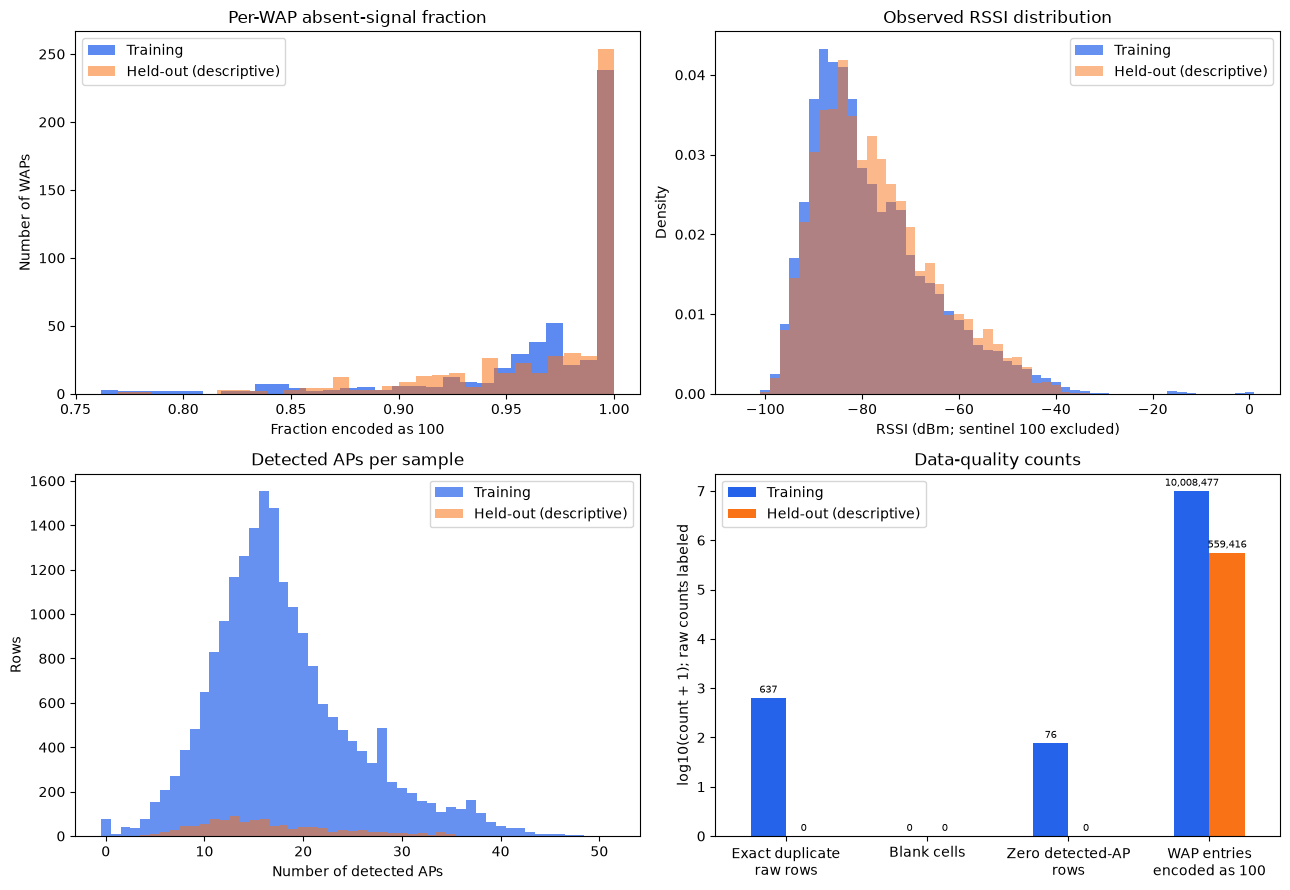

In [8]:
train_detected_counts = train_seen_array.sum(axis=1)
heldout_detected_counts = heldout_seen_array.sum(axis=1)
train_missing_by_ap = (~train_seen_array).mean(axis=0)
heldout_missing_by_ap = (~heldout_seen_array).mean(axis=0)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes[0, 0].hist(train_missing_by_ap, bins=30, alpha=0.75, label="Training", color="#2563eb")
axes[0, 0].hist(heldout_missing_by_ap, bins=30, alpha=0.55, label="Held-out (descriptive)", color="#f97316")
axes[0, 0].set(title="Per-WAP absent-signal fraction", xlabel="Fraction encoded as 100", ylabel="Number of WAPs")
axes[0, 0].legend()
axes[0, 1].hist(train_observed_values, bins=np.arange(-105, 2, 2), alpha=0.7, density=True, label="Training", color="#2563eb")
axes[0, 1].hist(heldout_observed_values, bins=np.arange(-105, 2, 2), alpha=0.5, density=True, label="Held-out (descriptive)", color="#f97316")
axes[0, 1].set(title="Observed RSSI distribution", xlabel="RSSI (dBm; sentinel 100 excluded)", ylabel="Density")
axes[0, 1].legend()
max_detected = int(max(train_detected_counts.max(), heldout_detected_counts.max()))
integer_bins = np.arange(-0.5, max_detected + 1.5, 1)
axes[1, 0].hist(train_detected_counts, bins=integer_bins, alpha=0.7, label="Training", color="#2563eb")
axes[1, 0].hist(heldout_detected_counts, bins=integer_bins, alpha=0.55, label="Held-out (descriptive)", color="#f97316")
axes[1, 0].set(title="Detected APs per sample", xlabel="Number of detected APs", ylabel="Rows")
axes[1, 0].legend()
quality_plot = quality_summary.set_index("check")[["training", "heldout_descriptive"]]
quality_log_plot = np.log10(quality_plot + 1)
quality_log_plot.plot(kind="bar", ax=axes[1, 1], color=["#2563eb", "#f97316"])
axes[1, 1].set(title="Data-quality counts", xlabel="", ylabel="log10(count + 1); raw counts labeled")
axes[1, 1].set_xticklabels(["Exact duplicate\nraw rows", "Blank cells", "Zero detected-AP\nrows", "WAP entries\nencoded as 100"], rotation=0)
for group_index, container in enumerate(axes[1, 1].containers):
    raw_counts = quality_plot.iloc[:, group_index].to_numpy()
    axes[1, 1].bar_label(container, labels=[f"{int(v):,}" for v in raw_counts], fontsize=7, padding=2)
axes[1, 1].legend(["Training", "Held-out (descriptive)"])
fig.tight_layout()
fig.savefig(FIGURES_DIR / "ml_01_data_quality_eda.png", dpi=160, bbox_inches="tight")
plt.show()



**Cell purpose:** Plots building and floor label counts for the supplied partitions.


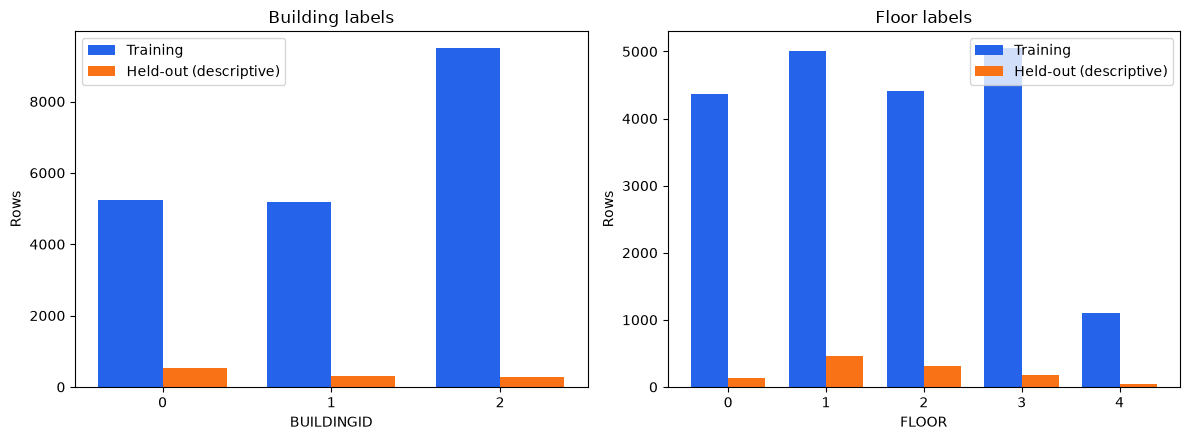

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, label, title in [(axes[0], "BUILDINGID", "Building labels"), (axes[1], "FLOOR", "Floor labels")]:
    train_counts = train_raw[label].value_counts().sort_index()
    heldout_counts = heldout_raw[label].value_counts().sort_index()
    labels = sorted(set(train_counts.index) | set(heldout_counts.index))
    x = np.arange(len(labels))
    width = 0.38
    ax.bar(x - width/2, [train_counts.get(v, 0) for v in labels], width, label="Training", color="#2563eb")
    ax.bar(x + width/2, [heldout_counts.get(v, 0) for v in labels], width, label="Held-out (descriptive)", color="#f97316")
    ax.set(title=title, xlabel=label, ylabel="Rows", xticks=x, xticklabels=labels)
    ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "ml_01_target_distribution_eda.png", dpi=160, bbox_inches="tight")
plt.show()



**Cell purpose:** Plots raw coordinate labels by building for descriptive inspection.


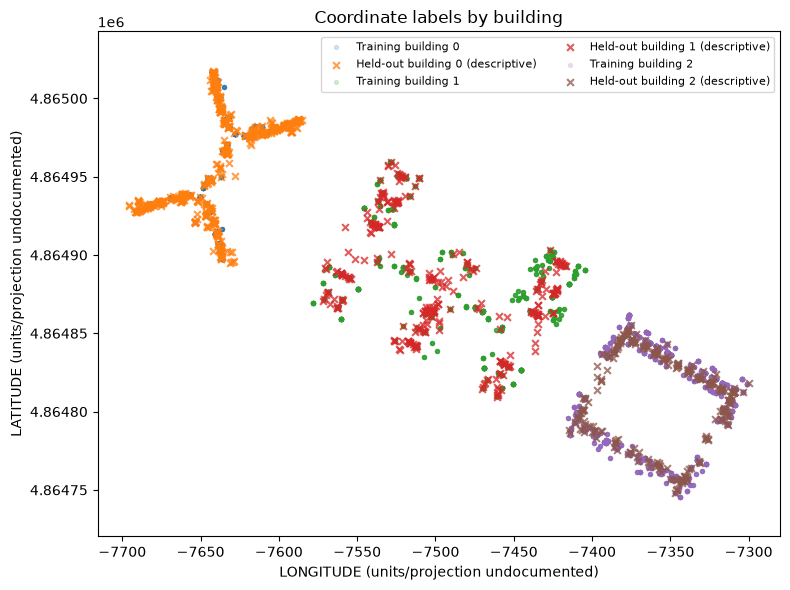

In [10]:
fig, ax = plt.subplots(figsize=(8, 6))
for building in sorted(train_raw.BUILDINGID.unique()):
    train_building = train_raw[train_raw.BUILDINGID == building]
    heldout_building = heldout_raw[heldout_raw.BUILDINGID == building]
    ax.scatter(train_building.LONGITUDE, train_building.LATITUDE, s=8, alpha=0.18, label=f"Training building {building}")
    ax.scatter(heldout_building.LONGITUDE, heldout_building.LATITUDE, s=24, alpha=0.75, marker="x", label=f"Held-out building {building} (descriptive)")
ax.set(title="Coordinate labels by building", xlabel="LONGITUDE (units/projection undocumented)", ylabel="LATITUDE (units/projection undocumented)")
ax.legend(fontsize=8, ncol=2)
ax.set_aspect("equal", adjustable="datalim")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "ml_01_coordinate_labels_eda.png", dpi=160, bbox_inches="tight")
plt.show()


## 5. Shared AML development split

The existing building-classification notebook uses `GroupShuffleSplit` with a 20% internal holdout, seed 42, and groups formed from `(BUILDINGID, FLOOR, SPACEID)`. This notebook uses that same contract against the verified raw training partition and retains duplicate rows. The other AML notebooks have inconsistent/stale file expectations, so downstream model notebooks should consume the artifacts generated here and use this split unchanged.


**Cell purpose:** Defines and checks the shared group-based development split.


In [11]:
GROUP_COLUMNS = ["BUILDINGID", "FLOOR", "SPACEID"]
GROUP_TEST_SIZE = 0.20
GROUP_RANDOM_STATE = 42
group_keys = (train_raw["BUILDINGID"].astype(str) + "_" + train_raw["FLOOR"].astype(str) + "_" + train_raw["SPACEID"].astype(str))
splitter = GroupShuffleSplit(n_splits=1, test_size=GROUP_TEST_SIZE, random_state=GROUP_RANDOM_STATE)
internal_train_positions, internal_validation_positions = next(splitter.split(train_raw, groups=group_keys))
# Recreate the split to make the seed and row assignment an explicit smoke check.
splitter_check = GroupShuffleSplit(n_splits=1, test_size=GROUP_TEST_SIZE, random_state=GROUP_RANDOM_STATE)
train_positions_check, validation_positions_check = next(splitter_check.split(train_raw, groups=group_keys))
assert np.array_equal(internal_train_positions, train_positions_check)
assert np.array_equal(internal_validation_positions, validation_positions_check)
internal_train_raw = train_raw.iloc[internal_train_positions].copy()
internal_validation_raw = train_raw.iloc[internal_validation_positions].copy()
train_groups = set(group_keys.iloc[internal_train_positions])
validation_groups = set(group_keys.iloc[internal_validation_positions])
assert train_groups.isdisjoint(validation_groups)
assert set(internal_train_raw.ROW_ID).isdisjoint(set(internal_validation_raw.ROW_ID))
assert set(internal_train_raw.ROW_ID) | set(internal_validation_raw.ROW_ID) == set(train_raw.ROW_ID)
print("Group columns:", GROUP_COLUMNS, "| test_size:", GROUP_TEST_SIZE, "| random_state:", GROUP_RANDOM_STATE)
print("Distinct groups:", group_keys.nunique(), "| rows internal train/dev:", len(internal_train_raw), len(internal_validation_raw))
print("Building counts train/dev:", internal_train_raw.BUILDINGID.value_counts().sort_index().to_dict(), internal_validation_raw.BUILDINGID.value_counts().sort_index().to_dict())
print("Floor counts train/dev:", internal_train_raw.FLOOR.value_counts().sort_index().to_dict(), internal_validation_raw.FLOOR.value_counts().sort_index().to_dict())


Group columns: ['BUILDINGID', 'FLOOR', 'SPACEID'] | test_size: 0.2 | random_state: 42
Distinct groups: 735 | rows internal train/dev: 16085 3852
Building counts train/dev: {0: 4177, 1: 4102, 2: 7806} {0: 1072, 1: 1094, 2: 1686}
Floor counts train/dev: {0: 3569, 1: 3892, 2: 3592, 3: 4170, 4: 862} {0: 800, 1: 1110, 2: 824, 3: 878, 4: 240}


## 6. Train-only RSSI scaling and shared feature functions

Each WAP is standardized independently using mean and population standard deviation (`ddof=0`) over **observed values in the internal-training rows only**. A zero/undefined scale is replaced with 1. Missing `100` values are never treated as RSSI measurements. After scaling, absent values receive a per-WAP imputation value equal to the minimum scaled observed training value minus 1. For WAPs with no internal-training observations, the fallback mean and scale are the global mean and population standard deviation fitted over all observed internal-training RSSI entries; their missing fill is the corresponding global minimum z-score minus 1. A `SEEN__WAPnnn` indicator (1 observed, 0 absent) remains alongside every scaled signal column, so that the mask is authoritative if future observed data reaches an imputed value.

Per-row summaries are calculated from observed raw dBm: `n_heard`, `max_rssi_dbm`, `mean_rssi_dbm`, `std_rssi_dbm`, `n_strong` (observed signals greater than −70 dBm), and `top1_ap_index` (zero-based WAP index of strongest observed reading; `-1` when no AP is detected). Empty-signal rows use explicit finite summary fills and are never assigned a strongest AP.


**Cell purpose:** Defines the scaler that learns RSSI statistics from internal training only.


In [12]:
def fit_rssi_scaler(internal_train_frame, ap_columns=AP_COLUMNS, missing_signal=MISSING_SIGNAL):
    raw = internal_train_frame[ap_columns].to_numpy(dtype=np.float64, copy=True)
    observed = raw != missing_signal
    counts = observed.sum(axis=0)
    all_observed = raw[observed]
    if all_observed.size == 0:
        raise ValueError("Internal-training partition has no observed RSSI values")
    global_mean = all_observed.mean()
    global_std = all_observed.std(ddof=0)
    global_scale = global_std if global_std > 0 else 1.0
    global_standardized = (all_observed - global_mean) / global_scale
    global_impute = global_standardized.min() - 1.0
    means = np.full(len(ap_columns), global_mean, dtype=np.float64)
    scales = np.full(len(ap_columns), global_scale, dtype=np.float64)
    observed_stds = np.zeros(len(ap_columns), dtype=np.float64)
    impute_scaled = np.full(len(ap_columns), global_impute, dtype=np.float64)
    for j in range(len(ap_columns)):
        values = raw[observed[:, j], j]
        if values.size:
            means[j] = values.mean()
            scale = values.std(ddof=0)
            observed_stds[j] = scale
            scales[j] = scale if scale > 0 else 1.0
            standardized = (values - means[j]) / scales[j]
            impute_scaled[j] = standardized.min() - 1.0
    return {"ap_columns": list(ap_columns), "means": means, "scales": scales,
            "impute_scaled": impute_scaled, "observed_counts": counts, "observed_stds": observed_stds,
            "global_mean": global_mean, "global_scale": global_scale,
            "fit_row_ids": internal_train_frame.ROW_ID.to_numpy(copy=True),
            "fit_partition": "trainingData/internal_train"}



**Cell purpose:** Defines consistent RSSI scaling and missingness-indicator transformation.


In [13]:
def transform_wifi(frame, scaler, missing_signal=MISSING_SIGNAL):
    if list(scaler["ap_columns"]) != AP_COLUMNS:
        raise ValueError("Scaler WAP schema differs from this notebook's verified schema")
    raw = frame[AP_COLUMNS].to_numpy(dtype=np.float64, copy=True)
    seen = raw != missing_signal
    scaled = (raw - scaler["means"]) / scaler["scales"]
    scaled[~seen] = np.broadcast_to(scaler["impute_scaled"], scaled.shape)[~seen]
    rssi = pd.DataFrame(scaled.astype(np.float32), columns=[f"RSSI_Z__{ap}" for ap in AP_COLUMNS], index=frame.index)
    indicators = pd.DataFrame(seen.astype(np.uint8), columns=[f"SEEN__{ap}" for ap in AP_COLUMNS], index=frame.index)
    return rssi, indicators, raw, seen



**Cell purpose:** Defines row-level signal count and strength summary features.


In [14]:
def make_signal_summaries(raw, seen, index=None):
    n_heard = seen.sum(axis=1).astype(np.int16)
    has_signal = n_heard > 0
    observed = np.where(seen, raw, np.nan)
    strongest = np.full(len(raw), -110.0, dtype=np.float32)
    mean_signal = np.full(len(raw), -110.0, dtype=np.float32)
    std_signal = np.zeros(len(raw), dtype=np.float32)
    top1_index = np.full(len(raw), -1, dtype=np.int16)
    if has_signal.any():
        strongest[has_signal] = np.nanmax(observed[has_signal], axis=1).astype(np.float32)
        mean_signal[has_signal] = np.nanmean(observed[has_signal], axis=1).astype(np.float32)
        std_signal[has_signal] = np.nanstd(observed[has_signal], axis=1).astype(np.float32)
        top1_index[has_signal] = np.argmax(np.where(seen[has_signal], raw[has_signal], -np.inf), axis=1).astype(np.int16)
    n_strong = ((raw > -70.0) & seen).sum(axis=1).astype(np.int16)
    return pd.DataFrame({"n_heard": n_heard, "max_rssi_dbm": strongest,
                         "mean_rssi_dbm": mean_signal, "std_rssi_dbm": std_signal,
                         "n_strong": n_strong, "top1_ap_index": top1_index}, index=index)



**Cell purpose:** Fits the scaler on internal-training rows and records its fit provenance.


In [15]:
SCALER = fit_rssi_scaler(internal_train_raw)
assert SCALER["fit_partition"] == "trainingData/internal_train"
assert set(SCALER["fit_row_ids"]) == set(internal_train_raw.ROW_ID)
assert np.array_equal(np.sort(SCALER["fit_row_ids"]), np.sort(internal_train_raw.ROW_ID.to_numpy()))
print("Scaler fitted on internal training rows:", len(SCALER["fit_row_ids"]))
print("WAPs with no observed internal-training values (global train-only fallback):", int((SCALER["observed_counts"] == 0).sum()))
print("Example fitted mean/scale/imputation:", {"WAP001": (round(float(SCALER["means"][0]), 3), round(float(SCALER["scales"][0]), 3), round(float(SCALER["impute_scaled"][0]), 3))})


Scaler fitted on internal training rows: 16085
WAPs with no observed internal-training values (global train-only fallback): 69
Example fitted mean/scale/imputation: {'WAP001': (-95.25, 1.299, -1.577)}


## 7. Prepare the three shared datasets

Every output row preserves source row ID, source partition, all five collection metadata fields, all four targets, and the features in a fixed order. `FEATURE_COLUMNS` is the sole predictor allowlist; IDs, metadata, and targets are deliberately excluded.


**Cell purpose:** Defines the predictor allowlist and canonical output-column order.


In [16]:
FEATURE_COLUMNS = ([f"RSSI_Z__{ap}" for ap in AP_COLUMNS]
                   + [f"SEEN__{ap}" for ap in AP_COLUMNS]
                   + ["n_heard", "max_rssi_dbm", "mean_rssi_dbm", "std_rssi_dbm", "n_strong", "top1_ap_index"])
OUTPUT_METADATA_COLUMNS = ["ROW_ID", "SOURCE_PARTITION"] + METADATA_COLUMNS
OUTPUT_COLUMNS = OUTPUT_METADATA_COLUMNS + TARGET_COLUMNS + FEATURE_COLUMNS
assert len(FEATURE_COLUMNS) == 2 * len(AP_COLUMNS) + 6
assert not (set(FEATURE_COLUMNS) & set(OUTPUT_METADATA_COLUMNS + TARGET_COLUMNS))



**Cell purpose:** Defines reusable preparation for one source partition.


In [17]:
def prepare_split(frame, source_partition, scaler=SCALER):
    rssi_scaled, seen_indicators, raw_signals, seen_mask = transform_wifi(frame, scaler)
    summaries = make_signal_summaries(raw_signals, seen_mask, index=frame.index)
    retained = frame[["ROW_ID"] + METADATA_COLUMNS + TARGET_COLUMNS].copy()
    retained.insert(1, "SOURCE_PARTITION", source_partition)
    prepared = pd.concat([retained, rssi_scaled, seen_indicators, summaries], axis=1)[OUTPUT_COLUMNS]
    feature_values = prepared[FEATURE_COLUMNS].to_numpy(dtype=np.float64)
    if not np.isfinite(feature_values).all():
        raise AssertionError("Prepared predictors contain NaN or infinite values")
    if not set(np.unique(prepared[[f"SEEN__{ap}" for ap in AP_COLUMNS]].to_numpy())).issubset({0, 1}):
        raise AssertionError("Seen indicators are not binary")
    return prepared



**Cell purpose:** Builds internal-training, internal-validation, and held-out feature tables.


In [18]:
internal_train = prepare_split(internal_train_raw, "trainingData")
internal_validation = prepare_split(internal_validation_raw, "trainingData")
heldout_validation = prepare_split(heldout_raw, "validationData")
assert len(internal_train) == len(internal_train_raw)
assert len(internal_validation) == len(internal_validation_raw)
assert len(heldout_validation) == len(heldout_raw)
assert all(frame.ROW_ID.is_unique for frame in [internal_train, internal_validation, heldout_validation])
assert set(internal_train.ROW_ID).isdisjoint(set(internal_validation.ROW_ID))
assert set(internal_train.ROW_ID) | set(internal_validation.ROW_ID) == set(train_raw.ROW_ID)
assert set(internal_train.SOURCE_PARTITION) == {"trainingData"}
assert set(internal_validation.SOURCE_PARTITION) == {"trainingData"}
assert set(heldout_validation.SOURCE_PARTITION) == {"validationData"}
assert all(c in internal_train.columns and c in heldout_validation.columns for c in TARGET_COLUMNS + OUTPUT_METADATA_COLUMNS)


**Cell purpose:** Checks train-only scaling, imputation, row counts, and partition labels.


In [19]:
# Verify the fitted standardization on observed internal-training readings only.
train_scaled_matrix = internal_train[[f"RSSI_Z__{ap}" for ap in AP_COLUMNS]].to_numpy(dtype=np.float64)
train_seen_matrix = internal_train[[f"SEEN__{ap}" for ap in AP_COLUMNS]].to_numpy(dtype=bool)
for j, ap in enumerate(AP_COLUMNS):
    values = train_scaled_matrix[train_seen_matrix[:, j], j]
    if values.size:
        assert abs(float(values.mean())) < 1e-5, f"Training scaled mean is not zero for {ap}"
        expected_std = 1.0 if SCALER["observed_stds"][j] > 0 else 0.0
        if values.size > 1:
            assert np.isclose(float(values.std(ddof=0)), expected_std, atol=1e-5), f"Training scaled standard deviation mismatch for {ap}"
        expected_imputed = SCALER["impute_scaled"][j]
        assert np.allclose(train_scaled_matrix[~train_seen_matrix[:, j], j], expected_imputed, atol=1e-6), f"Missing-value fill mismatch for {ap}"
print("Verified observed internal-training feature means are centered and nonconstant WAPs have unit population scale.")
print("Prepared dimensions:", {"internal_train": internal_train.shape, "internal_validation": internal_validation.shape, "heldout_validation": heldout_validation.shape})
print("Feature count:", len(FEATURE_COLUMNS), "| sample dtypes:", {c: str(internal_train[c].dtype) for c in ["RSSI_Z__WAP001", "SEEN__WAP001", "n_heard", "max_rssi_dbm", "top1_ap_index"]})


Verified observed internal-training feature means are centered and nonconstant WAPs have unit population scale.
Prepared dimensions: {'internal_train': (16085, 1057), 'internal_validation': (3852, 1057), 'heldout_validation': (1111, 1057)}
Feature count: 1046 | sample dtypes: {'RSSI_Z__WAP001': 'float32', 'SEEN__WAP001': 'uint8', 'n_heard': 'int16', 'max_rssi_dbm': 'float32', 'top1_ap_index': 'int16'}


## 8. Export plain CSV files, reload, and verify

CSV does not store pandas dtypes; feature floats are written as decimal numbers and readers may infer `float64`. The round-trip check verifies exact column order and row counts, numeric/finite predictors, binary masks, target/metadata availability, and source partition. Only after all replacement CSVs pass are the three obsolete shared preprocessing notebook `.csv.gz` files removed.


**Cell purpose:** Writes the canonical prepared datasets as CSV tables.


In [20]:
ARTIFACTS = {
    "aml_internal_train_features.csv": internal_train,
    "aml_internal_validation_features.csv": internal_validation,
    "aml_heldout_validation_features.csv": heldout_validation,
}
assert PROCESSED_DIR.is_dir()
for filename, frame in ARTIFACTS.items():
    output_path = PROCESSED_DIR / filename
    frame.to_csv(output_path, index=False)



**Cell purpose:** Reloads exported tables and checks schema, types, rows, and feature values.


In [21]:
# Reload all replacements before deleting any legacy compressed feature exports.
reloaded = {}
for filename, original in ARTIFACTS.items():
    loaded = pd.read_csv(PROCESSED_DIR / filename)
    assert loaded.shape == original.shape, f"Row/column count mismatch after reload: {filename}"
    assert loaded.columns.tolist() == OUTPUT_COLUMNS, f"Column order mismatch after reload: {filename}"
    assert loaded[FEATURE_COLUMNS].notna().all().all(), f"Missing feature values after reload: {filename}"
    assert np.isfinite(loaded[FEATURE_COLUMNS].to_numpy(dtype=np.float64)).all(), f"Nonfinite feature values after reload: {filename}"
    assert set(np.unique(loaded[[f"SEEN__{ap}" for ap in AP_COLUMNS]].to_numpy())).issubset({0, 1})
    assert loaded[TARGET_COLUMNS + OUTPUT_METADATA_COLUMNS].notna().all().all()
    assert loaded.SOURCE_PARTITION.eq(original.SOURCE_PARTITION.iloc[0]).all()
    assert loaded["ROW_ID"].is_unique
    assert all(pd.api.types.is_numeric_dtype(loaded[c]) for c in TARGET_COLUMNS + FEATURE_COLUMNS)
    integer_columns = ["ROW_ID", "SPACEID", "RELATIVEPOSITION", "USERID", "PHONEID", "TIMESTAMP", "BUILDINGID", "FLOOR", "n_heard", "n_strong", "top1_ap_index"] + [f"SEEN__{ap}" for ap in AP_COLUMNS]
    assert all(pd.api.types.is_integer_dtype(loaded[c]) for c in integer_columns)
    assert pd.api.types.is_float_dtype(loaded["LONGITUDE"]) and pd.api.types.is_float_dtype(loaded["LATITUDE"])
    reloaded[filename] = loaded
    print(filename, "rows:", len(loaded), "columns:", len(loaded.columns), "bytes:", (PROCESSED_DIR / filename).stat().st_size)



aml_internal_train_features.csv rows: 16085 columns: 1057 bytes: 104811260


aml_internal_validation_features.csv rows: 3852 columns: 1057 bytes: 25113238
aml_heldout_validation_features.csv rows: 1111 columns: 1057 bytes: 7248837


**Cell purpose:** Removes obsolete compressed exports and checks final table files.


In [22]:
OBSOLETE_COMPRESSED_EXPORTS = [
    "aml_internal_train_features.csv.gz",
    "aml_internal_validation_features.csv.gz",
    "aml_heldout_validation_features.csv.gz",
]
for filename in OBSOLETE_COMPRESSED_EXPORTS:
    obsolete_path = PROCESSED_DIR / filename
    if obsolete_path.exists():
        obsolete_path.unlink()



**Cell purpose:** Confirms canonical tables exist and reports split and scaler provenance.


In [23]:
assert all((PROCESSED_DIR / name).is_file() for name in ARTIFACTS)
assert all(not (PROCESSED_DIR / name).exists() for name in OBSOLETE_COMPRESSED_EXPORTS)
print("Validated plain CSVs; removed obsolete compressed feature files:", [name for name in OBSOLETE_COMPRESSED_EXPORTS if not (PROCESSED_DIR / name).exists()])
print("Shared split:", GROUP_COLUMNS, "| test_size:", GROUP_TEST_SIZE, "| random_state:", GROUP_RANDOM_STATE)
print("Scaler fit source: internal_train only; held-out data is transform-only.")


Validated plain CSVs; removed obsolete compressed feature files: ['aml_internal_train_features.csv.gz', 'aml_internal_validation_features.csv.gz', 'aml_heldout_validation_features.csv.gz']
Shared split: ['BUILDINGID', 'FLOOR', 'SPACEID'] | test_size: 0.2 | random_state: 42
Scaler fit source: internal_train only; held-out data is transform-only.


## Conclusion

- Consume `data/processed/aml_internal_train_features.csv`, `aml_internal_validation_features.csv`, and `aml_heldout_validation_features.csv` with `pandas.read_csv`.
- Use `FEATURE_COLUMNS` as the predictor allowlist. Targets are `BUILDINGID`, `FLOOR`, `LONGITUDE`, and `LATITUDE`. Metadata (`ROW_ID`, `SOURCE_PARTITION`, `SPACEID`, `RELATIVEPOSITION`, `USERID`, `PHONEID`, `TIMESTAMP`) must remain excluded from predictors by default.
- Match the shared `GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)` using the composite key `(BUILDINGID, FLOOR, SPACEID)` over raw `trainingData.csv`, retaining duplicate records. The held-out raw validation file is never part of this split or scaler fit.
- `LONGITUDE`/`LATITUDE` units or coordinate projection and semantics beyond field names are not documented in the repository. Validation `SPACEID`, `RELATIVEPOSITION`, and `USERID` are zero placeholders.
- Downstream model notebooks should consume the canonical artifacts exported here and preserve the documented split and feature contract.


**How to interpret these scores.** The supplied partition and grouped development split do not guarantee that every Wi-Fi fingerprint is unique across training and evaluation data; repeated two-dimensional coordinate values may also occur. Scores therefore describe performance under the current split and do not establish generalization to unseen fingerprints or unseen positions. The current research question uses the supplied split; adopt a stricter fingerprint- or position-grouped split only if that research question changes.

## Next Steps

Use the exported feature tables and `FEATURE_COLUMNS` contract in the building, floor, and coordinate pipelines. Keep the supplied validation partition held out for final evaluation and carry the fingerprint-overlap and repeated-coordinate caveats into score interpretation.